Reference shape: (3508, 2481, 3)
Defective shape: (3508, 2481, 3)


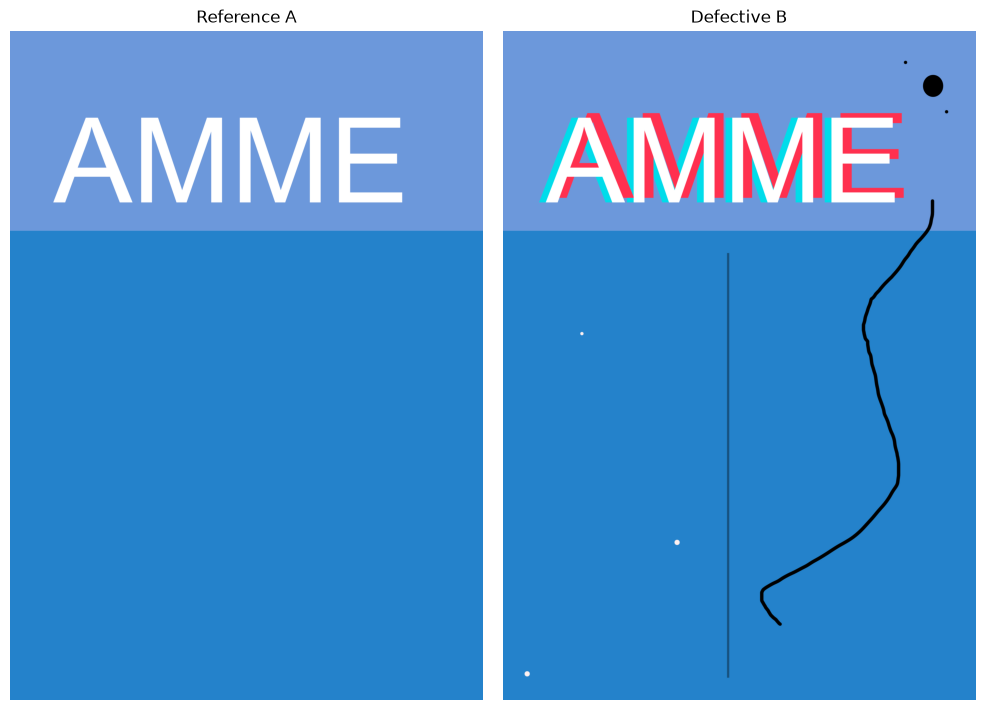

In [13]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Image folder
folder = Path(r"D:\AMME5710_Major_Project\Custom_test")

# Read two images
A = cv2.imread(str(folder / "Reference.png"))
B = cv2.imread(str(folder / "Defective.png"))

# Check images
if A is None or B is None:
    raise FileNotFoundError("Cannot read the images. Check the paths.")

if A.shape != B.shape:
    raise ValueError("Reference and defective images must have the same size.")

print("Reference shape:", A.shape)
print("Defective shape:", B.shape)

# Convert BGR to RGB for display
A_rgb = cv2.cvtColor(A, cv2.COLOR_BGR2RGB)
B_rgb = cv2.cvtColor(B, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(10, 7))

axes[0].imshow(A_rgb)
axes[0].set_title("Reference A")

axes[1].imshow(B_rgb)
axes[1].set_title("Defective B")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


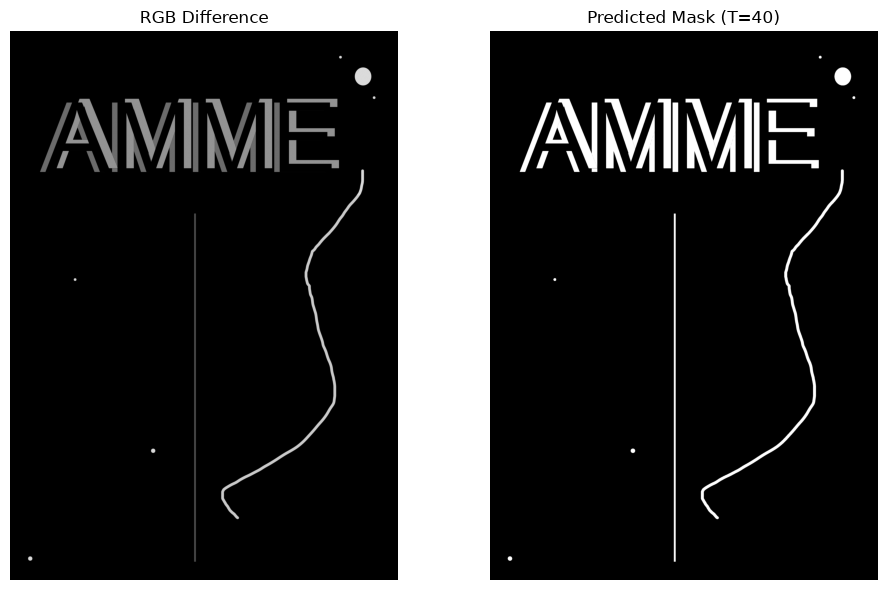

Detected pixels: 421394


In [14]:
# Calculate absolute difference in BGR channels
colour_diff = cv2.absdiff(A, B)

# Maximum difference among three channels
diff_rgb = np.max(colour_diff, axis=2)

# Threshold
T = 40

# Generate binary mask
pred_mask = (diff_rgb > T).astype(np.uint8) * 255

# Display results
fig, axes = plt.subplots(1, 2, figsize=(10, 6))

axes[0].imshow(diff_rgb, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("RGB Difference")

axes[1].imshow(pred_mask, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Predicted Mask (T={T})")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Detected pixels:", np.count_nonzero(pred_mask))

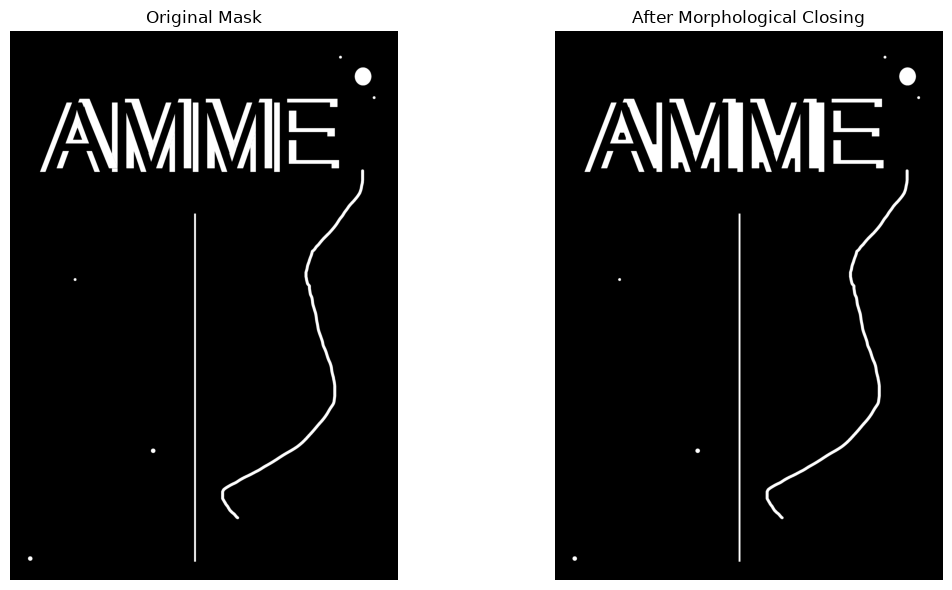

In [15]:
# Morphological Closing
kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    (25, 15)
)

closed_mask = cv2.morphologyEx(
    pred_mask,
    cv2.MORPH_CLOSE,
    kernel
)

# Compare before and after
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(pred_mask, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Mask")

axes[1].imshow(closed_mask, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("After Morphological Closing")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [11]:
# Find connected components
num_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        pred_mask,
        connectivity=8
    )
)

# Initial minimum area
min_area = 5

# Store candidate regions
candidates = []

for label_id in range(1, num_labels):

    x, y, w, h, area = stats[label_id]

    # Ignore very small components
    if area < min_area:
        continue

    candidates.append({
        "id": label_id,
        "x": int(x),
        "y": int(y),
        "w": int(w),
        "h": int(h),
        "area": int(area)
    })

# Sort by area
candidates = sorted(
    candidates,
    key=lambda c: c["area"],
    reverse=True
)

print("Total components:", num_labels - 1)
print("Remaining candidates:", len(candidates))

print("\nLargest candidates:")
for i, c in enumerate(candidates[:15]):
    print(
        f"{i+1}: Area={c['area']}, "
        f"Position=({c['x']}, {c['y']}), "
        f"Size={c['w']}x{c['h']}"
    )

Total components: 25
Remaining candidates: 25

Largest candidates:
1: Area=52322, Position=(1350, 883), Size=914x2236
2: Area=40028, Position=(435, 431), Size=253x468
3: Area=29961, Position=(735, 431), Size=297x403
4: Area=29959, Position=(1252, 431), Size=297x403
5: Area=22211, Position=(1072, 431), Size=87x445
6: Area=22211, Position=(1589, 431), Size=87x445
7: Area=20239, Position=(744, 522), Size=128x377
8: Area=20233, Position=(1261, 522), Size=128x377
9: Area=18792, Position=(1451, 528), Size=121x371
10: Area=18791, Position=(934, 528), Size=121x371
11: Area=15984, Position=(1689, 455), Size=36x444
12: Area=15983, Position=(1169, 455), Size=36x444
13: Area=15630, Position=(192, 455), Size=205x444
14: Area=15190, Position=(1783, 696), Size=321x180
15: Area=14068, Position=(1783, 507), Size=294x165


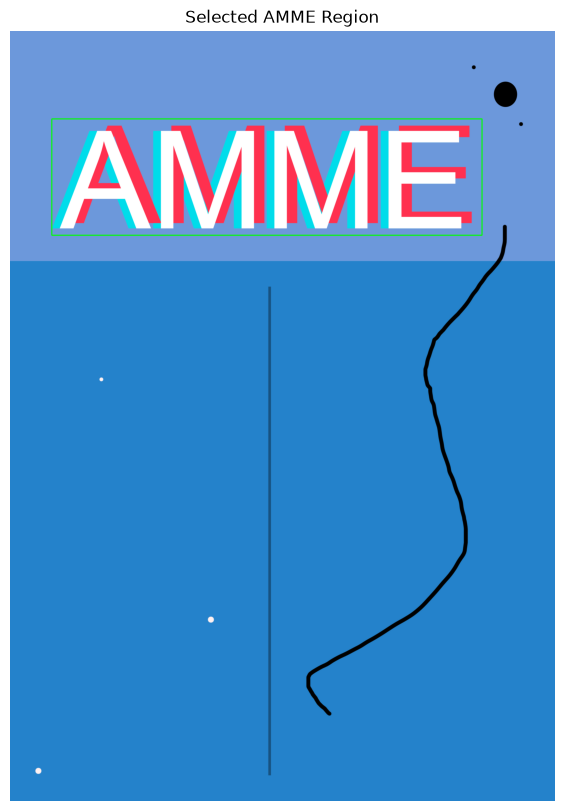

In [27]:
# AMME region based on component coordinates
x1, y1 = 190, 400
x2, y2 = 2150, 930

preview = B_rgb.copy()

cv2.rectangle(
    preview,
    (x1, y1),
    (x2, y2),
    (0, 255, 0),
    3
)

plt.figure(figsize=(8, 10))
plt.imshow(preview)
plt.title("Selected AMME Region")
plt.axis("off")
plt.show()

In [28]:
# 1. Extract the AMME region
text_mask = np.zeros_like(pred_mask)

text_mask[y1:y2, x1:x2] = pred_mask[y1:y2, x1:x2]

# 2. Remove AMME pixels from the remaining mask
remaining_mask = pred_mask.copy()
remaining_mask[y1:y2, x1:x2] = 0

# 3. Find independent components outside AMME
num_other, other_labels, other_stats, _ = (
    cv2.connectedComponentsWithStats(
        remaining_mask,
        connectivity=8
    )
)

# Store all region masks
region_masks = []

# AMME is treated as one logical region
if np.any(text_mask):
    region_masks.append({
        "name": "AMME Group",
        "mask": text_mask
    })

# Keep other components separate
min_area = 5

for label_id in range(1, num_other):

    area = other_stats[label_id, cv2.CC_STAT_AREA]

    if area < min_area:
        continue

    component_mask = np.zeros_like(pred_mask)
    component_mask[other_labels == label_id] = 255

    region_masks.append({
        "name": f"Region {label_id}",
        "mask": component_mask
    })

print("Total grouped regions:", len(region_masks))
print("AMME pixels:", np.count_nonzero(text_mask))


Total grouped regions: 9
AMME pixels: 330552


AMME Group: Position=(192,431), Size=1912x468
Region 1: Position=(2104,156), Size=18x18
Region 2: Position=(2204,230), Size=107x116
Region 3: Position=(2319,415), Size=18x18
Region 4: Position=(1350,883), Size=914x2236
Region 5: Position=(1177,1165), Size=12x2226
Region 6: Position=(407,1578), Size=18x18
Region 7: Position=(901,2667), Size=29x29
Region 8: Position=(115,3356), Size=29x29


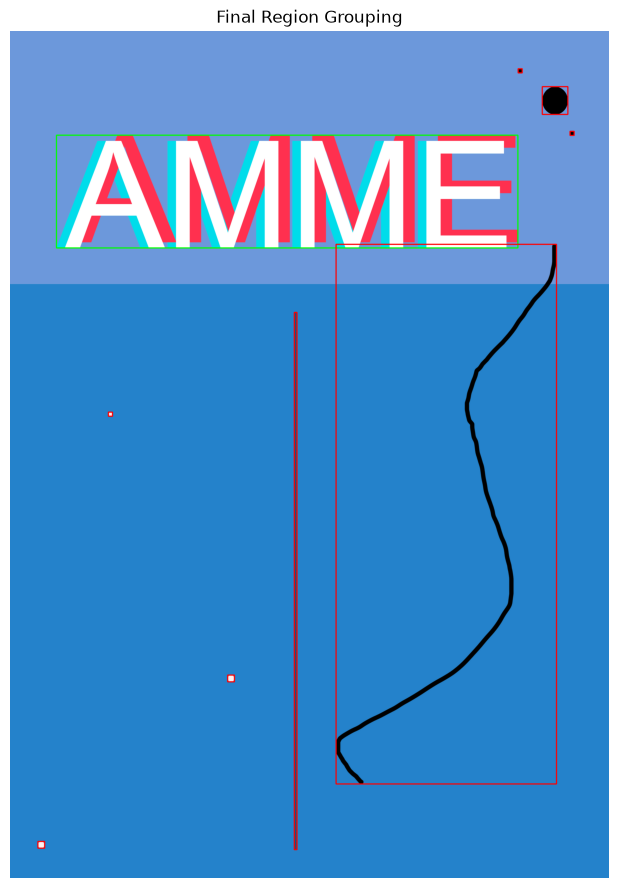

In [29]:
result = B_rgb.copy()

for i, region in enumerate(region_masks):

    mask = region["mask"]

    # Get the bounding rectangle
    points = cv2.findNonZero(mask)

    if points is None:
        continue

    x, y, w, h = cv2.boundingRect(points)

    # Green for grouped AMME, red for other regions
    color = (0, 255, 0) if i == 0 else (255, 0, 0)

    cv2.rectangle(
        result,
        (x, y),
        (x + w - 1, y + h - 1),
        color,
        3
    )

    print(
        f"{region['name']}: "
        f"Position=({x},{y}), "
        f"Size={w}x{h}"
    )

plt.figure(figsize=(8, 11))
plt.imshow(result)
plt.title("Final Region Grouping")
plt.axis("off")
plt.show()


In [31]:
import joblib
from skimage.feature import hog

# Load trained SVM
model_path = Path(
    r"D:\AMME5710_Major_Project\svm_classes.joblib"
)

model = joblib.load(model_path)

print("SVM model loaded successfully!")
print("Classes:", model.classes_)


SVM model loaded successfully!
Classes: ['blackspot' 'colorshift' 'hair' 'line' 'pinhole']


In [32]:
def extract_features(A, B, mask):

    gt = mask > 0

    if not np.any(gt):
        return None

    # Bounding box
    ys, xs = np.where(gt)

    x_min, x_max = xs.min(), xs.max()
    y_min, y_max = ys.min(), ys.max()

    width = x_max - x_min + 1
    height = y_max - y_min + 1

    # Add padding
    pad = 8

    x1 = max(0, x_min - pad)
    x2 = min(B.shape[1], x_max + pad + 1)

    y1 = max(0, y_min - pad)
    y2 = min(B.shape[0], y_max + pad + 1)

    # Colour difference
    diff = cv2.absdiff(A, B)

    # Crop local region
    diff_crop = diff[y1:y2, x1:x2]

    # HOG features
    diff_gray = cv2.cvtColor(
        diff_crop, cv2.COLOR_BGR2GRAY
    )

    diff_resized = cv2.resize(
        diff_gray,
        (32, 32),
        interpolation=cv2.INTER_AREA
    )

    hog_features = hog(
        diff_resized,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    )

    # Colour features
    defect_pixels = diff[gt].astype(np.float32)

    colour_features = np.concatenate([
        defect_pixels.mean(axis=0) / 255.0,
        defect_pixels.std(axis=0) / 255.0
    ])

    # Shape features
    area = np.count_nonzero(gt)

    shape_features = np.array([
        area / gt.size,
        width / B.shape[1],
        height / B.shape[0],
        width / max(height, 1)
    ], dtype=np.float32)

    # Combine all features
    features = np.concatenate([
        hog_features,
        colour_features,
        shape_features
    ])

    return features


In [33]:
# Store predictions
predictions = []

for i, region in enumerate(region_masks):

    mask = region["mask"]

    # Extract features from this region
    features = extract_features(A, B, mask)

    if features is None:
        continue

    # Predict defect category
    predicted_class = model.predict(
        features.reshape(1, -1)
    )[0]

    # Get bounding box
    points = cv2.findNonZero(mask)
    x, y, w, h = cv2.boundingRect(points)

    predictions.append({
        "region": region["name"],
        "category": predicted_class,
        "x": x,
        "y": y,
        "w": w,
        "h": h
    })

    print(
        f"{region['name']}: "
        f"{predicted_class}"
    )

print("\nTotal classified regions:", len(predictions))


AMME Group: colorshift
Region 1: blackspot
Region 2: hair
Region 3: blackspot
Region 4: hair
Region 5: colorshift
Region 6: blackspot
Region 7: hair
Region 8: hair

Total classified regions: 9


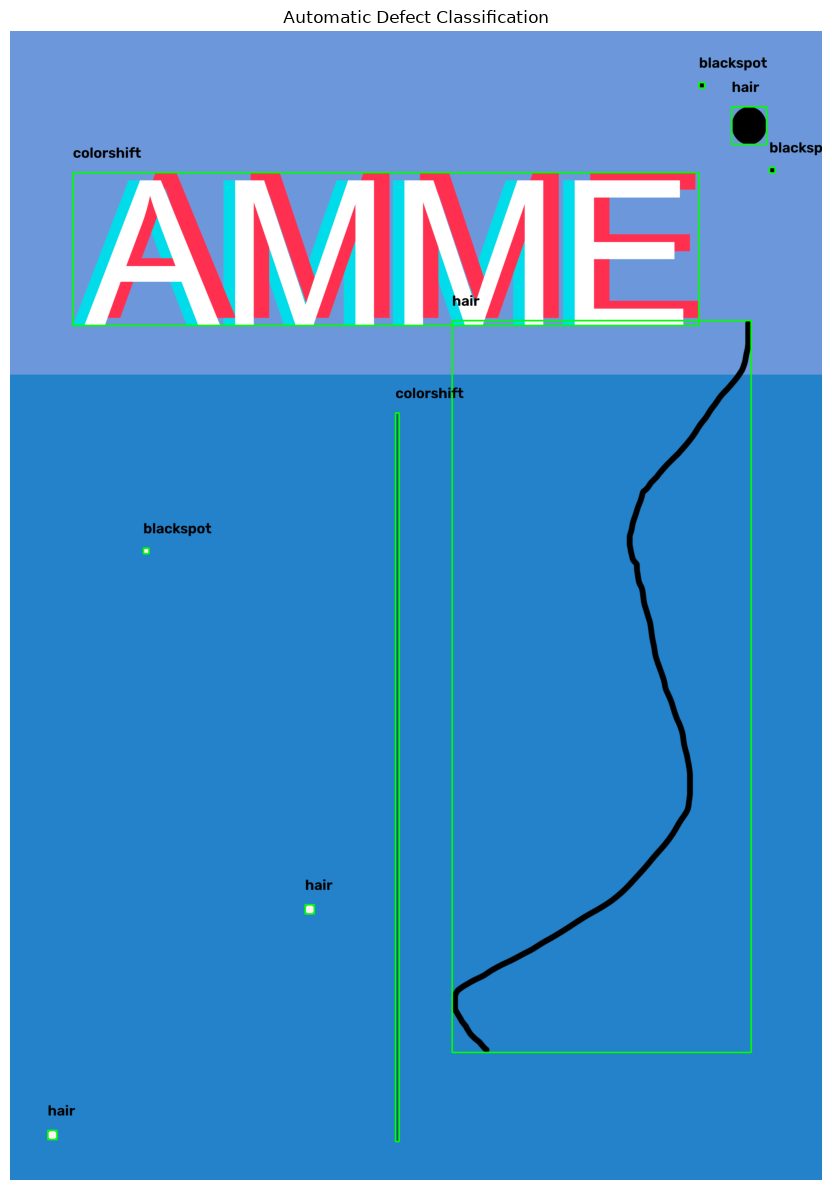

Saved to: D:\AMME5710_Major_Project\Custom_test\classified_result.png


In [36]:
# Copy original defective image (BGR)
annotated = B.copy()

for p in predictions:

    x = p["x"]
    y = p["y"]
    w = p["w"]
    h = p["h"]

    category = p["category"]

    # Draw bounding box
    cv2.rectangle(
        annotated,
        (x, y),
        (x + w - 1, y + h - 1),
        (0, 255, 0),
        3
    )

    # Draw predicted label
    cv2.putText(
        annotated,
        category,
        (x, max(45, y - 45)),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.5,
        (0, 0, 0),
        7
    )

# Convert for Matplotlib
annotated_rgb = cv2.cvtColor(
    annotated,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(9, 12))
plt.imshow(annotated_rgb)
plt.title("Automatic Defect Classification")
plt.axis("off")
plt.tight_layout()
plt.show()

# Save image
output_path = folder / "classified_result.png"

cv2.imwrite(str(output_path), annotated)

print("Saved to:", output_path)
